In [28]:
import os
import pandas as pd
from magic_mirrors import store

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.patches import Polygon, Patch
from magic_mirrors import geometry, store

In [3]:
! ls ../wyniki/kwiecien_maj/

kwiecien_maj  seg_check


In [57]:
out = "../wyniki/kwiecien_maj"
s = pd.read_parquet(f"{out}/scores.parquet")
_, _, meta, _ = store.load_features(out)
s["plik"] = s["frame"].map(lambda i: os.path.basename(meta["path"][i]))
t = s[s["split"] == "test"]

# lustra z alarmem w każdym kadrze testowym
print(t[t["alarm_max"]].groupby("plik")["idx"].apply(list).to_string())

# które lustra alarmowały w maju najczęściej
print(t.groupby("idx")["alarm_max"].sum().sort_values(ascending=False).head(15))

# miejsce luster 152 i 190 w rankingu każdego kadru (1 = najwyższy wynik)
t = t.assign(rank=t.groupby("frame")["score_max"].rank(ascending=False))
print(t[t["idx"].isin([152, 190])].pivot_table(index="plik", columns="idx", values="rank"))

plik
20240505_1000_la.jpg                                                 [38]
20240505_1020_la.jpg                                                 [38]
20240505_1030_la.jpg                                                 [38]
20240505_1430_la.jpg                                                [231]
20240505_1600_la.jpg                                        [9, 119, 152]
20240505_1630_la.jpg                                           [232, 233]
20240505_1640_la.jpg                                      [189, 231, 233]
20240505_1650_la.jpg                                      [189, 231, 233]
20240505_1700_la.jpg                                           [215, 233]
20240505_1710_la.jpg    [189, 190, 215, 217, 218, 219, 227, 228, 230, ...
20240505_1720_la.jpg    [32, 47, 188, 189, 190, 215, 227, 228, 231, 23...
20240505_1730_la.jpg                                           [189, 248]
20240505_1740_la.jpg          [32, 47, 189, 190, 215, 231, 232, 233, 248]
20240505_1750_la.jpg             

In [58]:
OUT = "../wyniki/kwiecien_maj"                 # katalog wyników
LABELS = "../input/labels.csv"          # z aplikacji do etykietowania (może nie istnieć)
POSITIVE = {"missing", "defocus", "changed"}
IGNORED = {"occluded", "uncertain"}

s = pd.read_parquet(f"{OUT}/scores.parquet")
_, _, meta, _ = store.load_features(OUT)
meta["plik"] = meta["path"].map(os.path.basename)
lab = pd.read_csv(LABELS) if os.path.exists(LABELS) else pd.DataFrame(columns=["frame", "idx", "label"])
POLYS = geometry.polygons()
CROP = (300, 585, 358, 45)                  # x0, x1, y1, y0 dla imshow (czasza)

In [59]:
def show_frame(name, variant="max", compare_days=None, annotate_top=8):
    """Kadr z wynikiem detektora, etykietami i metrykami dla tego kadru.
    name: fragment nazwy pliku, np. "20240507_1230"
    variant: cov / max / manhattan / mahalanobis
    compare_days: np. 1 -> obok kadr z tą samą godziną sprzed 1 dnia
    Zwraca (tabela 15 najwyższych wyników, słownik metryk).
    """
    hit = meta.index[meta["plik"].str.contains(name)]
    if len(hit) == 0:
        print("Kadru nie ma wśród dobrych (odrzucony w selekcji albo zła nazwa).")
        return
    i = hit[0]
    f = s[s["frame"] == i].set_index("idx").reindex(range(249))
    plik = meta["plik"][i]
    score, alarm = f[f"score_{variant}"].values, f[f"alarm_{variant}"].fillna(False).values.astype(bool)
    thr = f[f"thr_{variant}"].dropna().iloc[0] if f"thr_{variant}" in f and f[f"thr_{variant}"].notna().any() else np.nan
    L = lab[lab["frame"] == plik].set_index("idx")["label"]
    truth = np.array([L.get(k) in POSITIVE for k in range(249)])
    ignored = np.array([L.get(k) in IGNORED for k in range(249)])
    has_labels = len(L) > 0

    # --- metryki dla tego jednego kadru (lustra z wynikiem, bez occluded/uncertain) ---
    use = np.isfinite(score) & ~ignored
    y, p = truth[use], alarm[use]
    tp, fp = int((p & y).sum()), int((p & ~y).sum())
    fn, tn = int((~p & y).sum()), int((~p & ~y).sum())
    div = lambda a, b: a / b if b else float("nan")
    m = {"TP": tp, "FP": fp, "FN": fn, "TN": tn,
         "accuracy": div(tp + tn, tp + tn + fp + fn), "precision": div(tp, tp + fp),
         "recall": div(tp, tp + fn), "F1": div(2 * tp, 2 * tp + fp + fn)}
    fmt = lambda x: "—" if x != x else f"{x:.2f}"          # NaN -> kreska
    mtxt = (f"TP {tp}  FP {fp}  FN {fn}  TN {tn}   |   precision {fmt(m['precision'])}   "
            f"recall {fmt(m['recall'])}   F1 {fmt(m['F1'])}   accuracy {fmt(m['accuracy'])}")

    img = cv2.cvtColor(cv2.imread(meta["path"][i]), cv2.COLOR_BGR2RGB)
    n = 3 if compare_days else 2
    fig, ax = plt.subplots(1, n, figsize=(4.5 * n, 5.5))

    # 1) kadr: wykryte vs oznaczone
    a = ax[0]
    a.imshow(img); a.set_xlim(CROP[0], CROP[1]); a.set_ylim(CROP[2], CROP[3]); a.axis("off")
    for k, q in enumerate(POLYS):
        if ignored[k]:
            st = ("#e0e0e0", "--")                       # pominięte w ocenie
        elif has_labels and alarm[k] and truth[k]:
            st = ("#2ecc71", "-")                        # trafienie
        elif alarm[k]:
            st = ("#ff9f1a", "-")                        # alarm bez etykiety
        elif truth[k]:
            st = ("#ff2d55", "-")                        # przeoczone
        else:
            continue
        a.add_patch(Polygon(q, closed=True, fill=False, edgecolor=st[0], linestyle=st[1], linewidth=2.2))
        x, y0 = q.mean(0)
        a.text(x, y0, str(k), ha="center", va="center", fontsize=7, color="white", weight="bold",
               bbox=dict(boxstyle="round,pad=0.1", fc="black", alpha=0.55, lw=0))
    leg = [Patch(fc="none", ec="#ff9f1a", lw=2, label="alarm" + (" bez etykiety" if has_labels else ""))]
    if has_labels:
        leg = [Patch(fc="none", ec="#2ecc71", lw=2, label="alarm + etykieta (trafienie)"), leg[0],
               Patch(fc="none", ec="#ff2d55", lw=2, label="etykieta bez alarmu (przeoczone)"),
               Patch(fc="none", ec="#e0e0e0", lw=2, ls="--", label="occluded / uncertain")]
    a.legend(handles=leg, loc="lower left", fontsize=8, framealpha=0.85)
    a.set_title(f"{plik}\nalarmy: {int(alarm.sum())}, referencji: {int(f['n_refs'].max())}" +
                ("" if has_labels else "  (brak etykiet dla tego kadru)"), fontsize=10)

    # 2) mapa wyniku
    a = ax[1]
    a.imshow(img); a.set_xlim(CROP[0], CROP[1]); a.set_ylim(CROP[2], CROP[3]); a.axis("off")
    v = np.where(np.isfinite(score), score, np.nan)
    vmax = np.nanmax([np.nanpercentile(v, 99), thr if np.isfinite(thr) else 0]) if np.isfinite(v).any() else 1
    pc = PolyCollection(POLYS, array=np.nan_to_num(v, nan=0), cmap="magma", edgecolors="white", linewidths=0.2, alpha=0.85)
    pc.set_clim(0, vmax); a.add_collection(pc)
    for k in np.argsort(-np.nan_to_num(v, nan=-1))[:annotate_top]:
        x, y0 = POLYS[k].mean(0)
        a.text(x, y0, str(k), ha="center", va="center", fontsize=7, color="cyan", weight="bold")
    cb = fig.colorbar(pc, ax=a, fraction=0.046)
    if np.isfinite(thr):
        cb.ax.axhline(thr, color="cyan", lw=2)
        cb.ax.text(1.6, thr, "próg", color="cyan", va="center", fontsize=8, transform=cb.ax.get_yaxis_transform())
    a.set_title(f"wynik ({variant}); brak wyniku = czarne", fontsize=10)

    # 3) opcjonalnie kadr porównawczy
    if compare_days:
        t0 = meta["time"][i]
        cand = meta[(meta["time"] - (t0 - pd.Timedelta(days=compare_days))).abs() <= pd.Timedelta(minutes=30)]
        a = ax[2]; a.axis("off")
        if len(cand):
            j = (cand["time"] - (t0 - pd.Timedelta(days=compare_days))).abs().idxmin()
            a.imshow(cv2.cvtColor(cv2.imread(meta["path"][j]), cv2.COLOR_BGR2RGB))
            a.set_xlim(CROP[0], CROP[1]); a.set_ylim(CROP[2], CROP[3]); a.set_title(f"porównanie: {meta['plik'][j]}", fontsize=10)
        else:
            a.set_title(f"brak dobrego kadru ±30 min sprzed {compare_days} dni", fontsize=10)

    if has_labels:
        fig.text(0.5, 0.01, mtxt, ha="center", fontsize=11,
                 bbox=dict(boxstyle="round,pad=0.4", fc="#eef3fb", ec="#1f6feb", lw=1))
        plt.tight_layout(rect=(0, 0.05, 1, 0.97))
    else:
        plt.tight_layout()
    plt.show()
    if has_labels:
        print(mtxt)

    # tabela: najwyższe wyniki z etykietami
    tab = pd.DataFrame({"idx": range(249), "wynik": score, "alarm": alarm,
                        "sat_frac": f["sat_frac"].values, "etykieta": [L.get(k, "") for k in range(249)]})
    return tab.sort_values("wynik", ascending=False).head(15).reset_index(drop=True), m

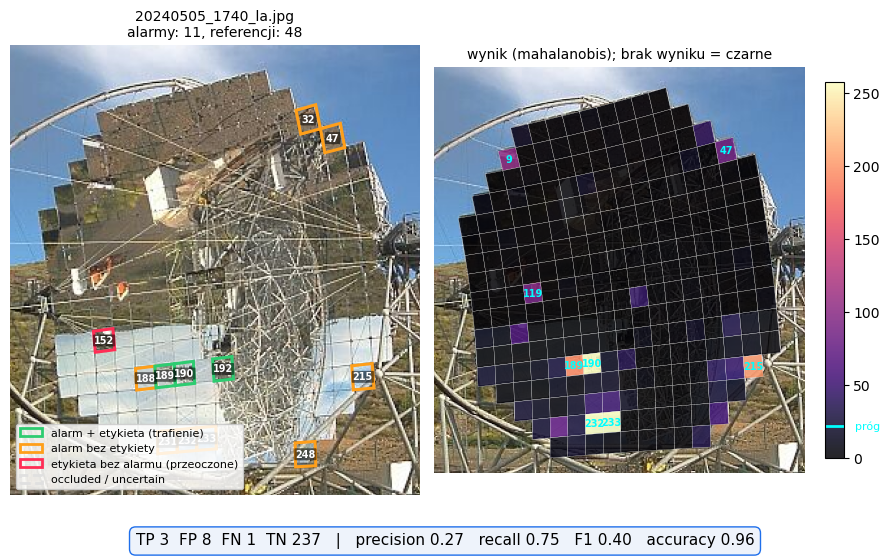

TP 3  FP 8  FN 1  TN 237   |   precision 0.27   recall 0.75   F1 0.40   accuracy 0.96


In [60]:
t, m = show_frame("20240505_1740", variant="mahalanobis")

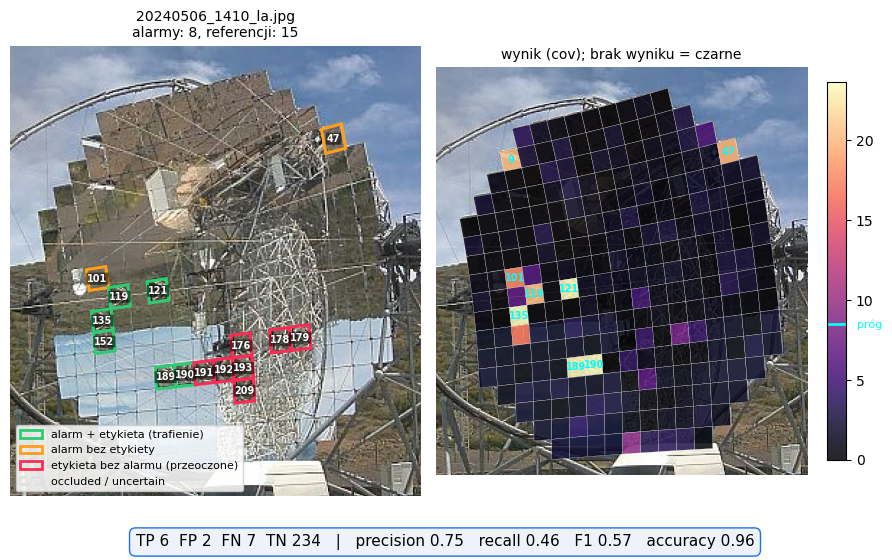

TP 6  FP 2  FN 7  TN 234   |   precision 0.75   recall 0.46   F1 0.57   accuracy 0.96


{'TP': 6,
 'FP': 2,
 'FN': 7,
 'TN': 234,
 'accuracy': 0.963855421686747,
 'precision': 0.75,
 'recall': 0.46153846153846156,
 'F1': 0.5714285714285714}

In [61]:
t, m = show_frame("20240506_1410", variant="cov")
m

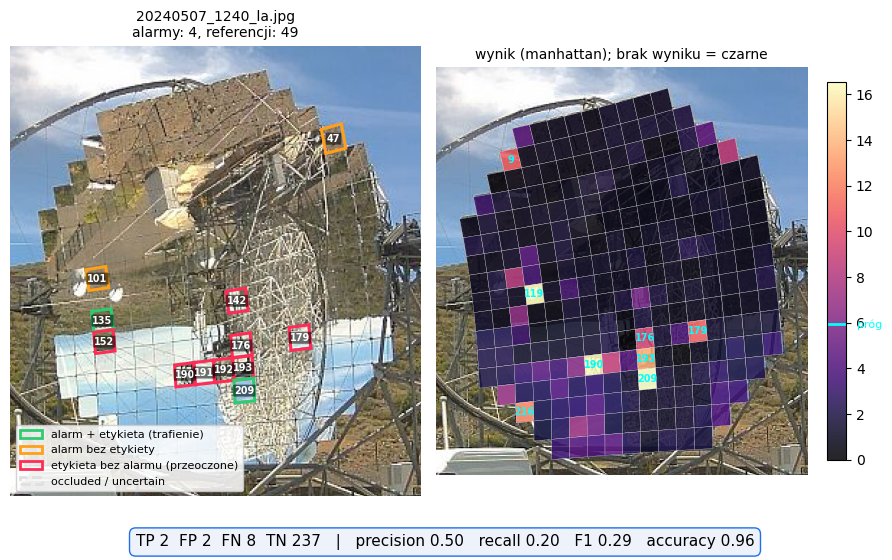

TP 2  FP 2  FN 8  TN 237   |   precision 0.50   recall 0.20   F1 0.29   accuracy 0.96


(    idx      wynik  alarm  sat_frac etykieta
 0   190  23.962521  False  0.223140  defocus
 1   119  20.281736  False  0.306306         
 2   209  19.126513   True  0.000000  defocus
 3   193  13.725265  False  0.133858  defocus
 4   216  12.146320  False  0.377953         
 5   179  10.812625  False  0.187970  defocus
 6     9  10.701262  False  0.241667         
 7   176   9.293590  False  0.060150  defocus
 8   191   8.680778  False  0.239669  defocus
 9    47   8.211728   True  0.000000         
 10  101   7.984262   True  0.000000         
 11  231   7.436928  False  0.008333         
 12  201   6.892283  False  0.051724         
 13  135   6.368592   True  0.008929  defocus
 14  189   6.161521  False  0.239316         ,
 {'TP': 2,
  'FP': 2,
  'FN': 8,
  'TN': 237,
  'accuracy': 0.9598393574297188,
  'precision': 0.5,
  'recall': 0.2,
  'F1': 0.2857142857142857})

In [42]:
show_frame("20240507_1240", variant="manhattan")

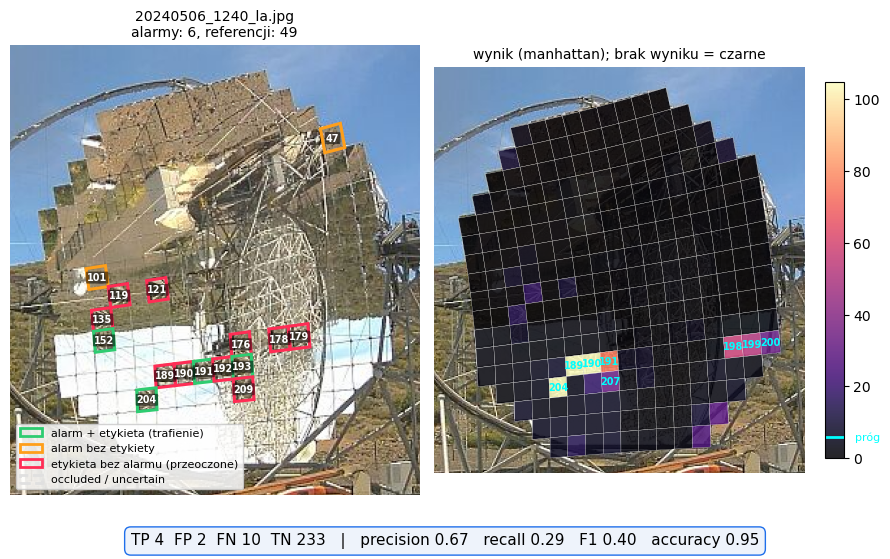

TP 4  FP 2  FN 10  TN 233   |   precision 0.67   recall 0.29   F1 0.40   accuracy 0.95


In [44]:
t, m = show_frame("20240506_1240", variant="manhattan")

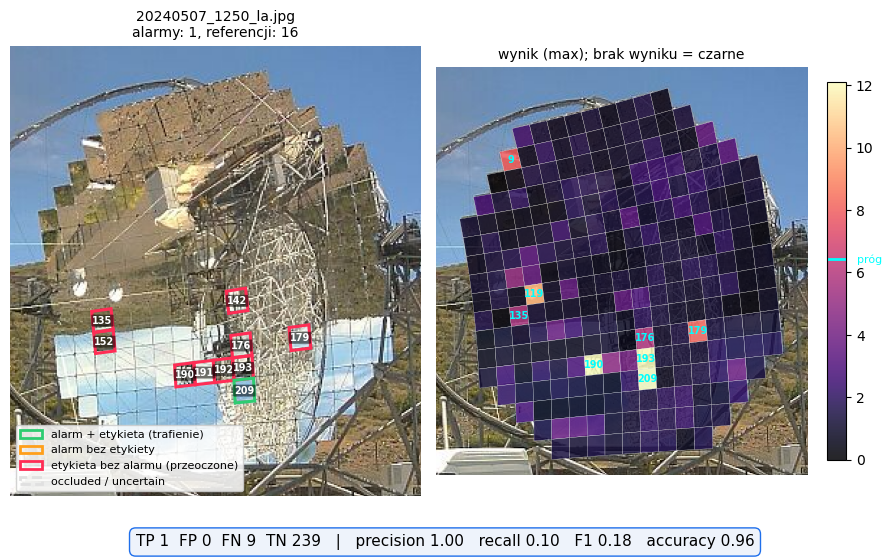

TP 1  FP 0  FN 9  TN 239   |   precision 1.00   recall 0.10   F1 0.18   accuracy 0.96


{'TP': 1,
 'FP': 0,
 'FN': 9,
 'TN': 239,
 'accuracy': 0.963855421686747,
 'precision': 1.0,
 'recall': 0.1,
 'F1': 0.18181818181818182}

In [62]:
t, m = show_frame("20240507_1250", variant="max") 
m

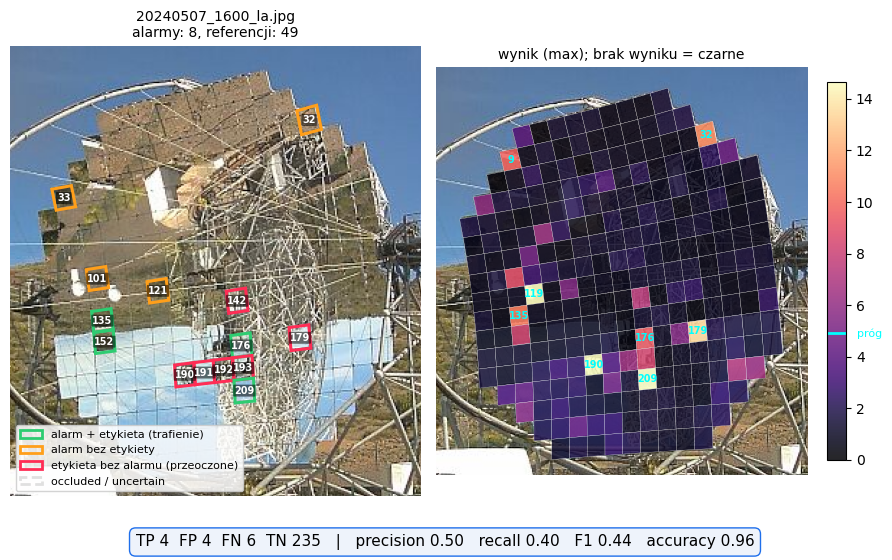

TP 4  FP 4  FN 6  TN 235   |   precision 0.50   recall 0.40   F1 0.44   accuracy 0.96


{'TP': 4,
 'FP': 4,
 'FN': 6,
 'TN': 235,
 'accuracy': 0.9598393574297188,
 'precision': 0.5,
 'recall': 0.4,
 'F1': 0.4444444444444444}

In [55]:
t, m = show_frame("20240507_1600", variant="max") 
m

In [64]:
from sklearn.metrics import confusion_matrix, average_precision_score

REVIEWED = "../input/reviewed.csv"
reviewed = set(pd.read_csv(REVIEWED)["frame"])

def eval_table(split="test"):
    """Dane do oceny: przejrzane kadry z danego splitu, lustra z wynikiem, bez occluded/uncertain."""
    e = s[s["split"] == split].copy()
    e["plik"] = e["frame"].map(meta["plik"])
    e = e[e["plik"].isin(reviewed)]
    e = e.merge(lab[["frame", "idx", "label"]].rename(columns={"frame": "plik"}), on=["plik", "idx"], how="left")
    e = e[~e["label"].isin(IGNORED)]
    e["y"] = e["label"].isin(POSITIVE)
    return e

def metrics(e, variant="max"):
    m = e[e[f"score_{variant}"].notna()]
    y, p = m["y"].values, m[f"alarm_{variant}"].fillna(False).values.astype(bool)
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[False, True]).ravel()
    div = lambda a, b: a / b if b else float("nan")
    return {"wariant": variant, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "accuracy": div(tp + tn, tp + tn + fp + fn),
            "precision": div(tp, tp + fp),
            "recall": div(tp, tp + fn),
            "F1": div(2 * tp, 2 * tp + fp + fn),
            "specificity": div(tn, tn + fp),
            "FP_na_kadr": div(fp, m["plik"].nunique()),
            "AUPRC": average_precision_score(y, m[f"score_{variant}"]) if y.any() else float("nan"),
            "AUPRC_losowo": y.mean()}

e = eval_table("test")
print(f"kadrów: {e['plik'].nunique()}, luster ocenionych: {e['score_max'].notna().sum()}, anomalii: {int(e['y'].sum())}")
variants = [c[6:] for c in s.columns if c.startswith("score_")]
res = pd.DataFrame([metrics(e, v) for v in variants]).set_index("wariant")
res.round(3)

kadrów: 111, luster ocenionych: 27399, anomalii: 885


,TP,FP,FN,TN,accuracy,precision,recall,F1,specificity,FP_na_kadr,AUPRC,AUPRC_losowo
wariant,,,,,,,,,,,,
cov,362,358,523,26156,0.968,0.503,0.409,0.451,0.986,3.225,0.488,0.032
max,295,150,590,26364,0.973,0.663,0.333,0.444,0.994,1.351,0.403,0.032
manhattan,358,216,527,26298,0.973,0.624,0.405,0.491,0.992,1.946,0.462,0.032
mahalanobis,354,157,531,26357,0.975,0.693,0.400,0.507,0.994,1.414,0.432,0.032


In [8]:
REVIEWED = "../input/reviewed.csv"
reviewed = set(pd.read_csv(REVIEWED)["frame"])

e = eval_table("test")
print(f"kadrów: {e['plik'].nunique()}, luster ocenionych: {e['score_max'].notna().sum()}, anomalii: {int(e['y'].sum())}")
variants = [c[6:] for c in s.columns if c.startswith("score_")]
res = pd.DataFrame([metrics(e, v) for v in variants]).set_index("wariant")
res.round(3)

kadrów: 9, luster ocenionych: 2241, anomalii: 72


,TP,FP,FN,TN,accuracy,precision,recall,F1,specificity,FP_na_kadr,AUPRC,AUPRC_losowo
wariant,,,,,,,,,,,,
cov,28,62,44,2107,0.953,0.311,0.389,0.346,0.971,6.889,0.574,0.032
max,32,101,40,2068,0.937,0.241,0.444,0.312,0.953,11.222,0.376,0.032
manhattan,32,114,40,2055,0.931,0.219,0.444,0.294,0.947,12.667,0.471,0.032
mahalanobis,32,108,40,2061,0.934,0.229,0.444,0.302,0.950,12.000,0.443,0.032


In [28]:
def at_threshold(e, variant="max", thresholds=None):
    """Precision i recall przy różnych progach (bez wymogu trwałości i veta - surowy wynik)."""
    m = e[e[f"score_{variant}"].notna()]
    y, sc = m["y"].values, m[f"score_{variant}"].values
    thresholds = thresholds if thresholds is not None else np.quantile(sc, [0.9, 0.95, 0.98, 0.99, 0.995, 0.999])
    rows = []
    for t in thresholds:
        p = sc > t; tp = (p & y).sum(); fp = (p & ~y).sum(); fn = (~p & y).sum()
        rows.append({"próg": t, "precision": tp / (tp + fp) if tp + fp else np.nan,
                     "recall": tp / (tp + fn) if tp + fn else np.nan,
                     "FP_na_kadr": fp / m["plik"].nunique()})
    return pd.DataFrame(rows)

def per_label_recall(e, variant="max"):
    m = e[e["y"] & e[f"score_{variant}"].notna()]
    return m.groupby("label")[f"alarm_{variant}"].agg(n="size", recall="mean")

display(at_threshold(e, "max").round(3))
display(per_label_recall(e, "max"))

,próg,precision,recall,FP_na_kadr
0,8.147,0.228,0.708,19.222
1,12.032,0.312,0.486,8.556
2,22.483,0.378,0.236,3.111
3,60.951,0.522,0.167,1.222
4,144.434,0.833,0.139,0.222
5,336.514,1.000,0.042,0.000


,n,recall
label,,
defocus,22,0.318182
missing,50,0.420000


In [29]:
v = "max"
m = e[e[f"score_{v}"].notna()].copy()
m["rank"] = m.groupby("plik")[f"score_{v}"].rank(ascending=False)
thr = s[f"thr_{v}"].dropna().iloc[0]

# 1. przeoczone lustra: czy mają wysoki wynik (zgubione przez próg/veto/trwałość) czy niski (brak sygnału)
fn = m[m["y"] & ~m[f"alarm_{v}"].astype(bool)]
print(fn.groupby(["idx", "label"]).agg(kadrow=("plik", "size"), wynik_med=(f"score_{v}", "median"),
      rank_med=("rank", "median"), powyzej_progu=(f"score_{v}", lambda x: (x > thr).mean()),
      sat_frac_med=("sat_frac", "median")).round(2))

# 2. fałszywe alarmy: czy to ciągle te same lustra
fp = m[~m["y"] & m[f"alarm_{v}"].astype(bool)]
print(fp.groupby("idx").size().sort_values(ascending=False).head(10))

             kadrow   wynik_med  rank_med  powyzej_progu  sat_frac_med
idx label                                                             
119 missing       2   16.879999      11.5           1.00          0.05
121 missing       2   17.889999      12.5           1.00          0.04
135 missing       3   17.600000      13.0           1.00          0.07
152 defocus       4   11.120000      11.0           1.00          0.06
    missing       1    6.890000      29.0           1.00          0.00
175 defocus       1    2.080000      75.0           0.00          0.07
176 defocus       1    5.170000      39.0           0.00          0.05
    missing       2    3.940000      53.0           0.00          0.04
178 defocus       1    3.260000      64.0           0.00          0.05
    missing       3    4.030000      52.0           0.00          0.06
179 defocus       1    3.750000      51.0           0.00          0.01
    missing       3    4.480000      50.0           0.33          0.03
189 de